# I Know a Spot: From Travel Post to Itinerary

Travel inspiration posts are full of ideas but short on details. They usually have no address and no link, so you can't tell where things are or whether the day is walkable.

This notebook analyzes one shared 9-day Japan itinerary (39 stops). I typed every stop in by hand, loaded it into SQLite, and used SQL and Python to answer two questions:
1. How many stops can actually be matched to a real location?
2. Does the order of stops in a day make the day longer than it needs to be?

**Limits:** coordinates are approximate (I spot-checked 15 of the 32 distinct places and corrected 2). Distances are straight-line, not walking or transit time. This is one itinerary, so the results are not general.

## The Data
Each row is one stop: day, city, order, place, category, latitude, longitude.
- Stops with no coordinates (like "Bullet Train to Kyoto" or "Morning in Osaka") are left blank because they aren't places.
- The image labels the Osaka day "Day 5" a second time. I assumed it is Day 6.
- TeamLab Borderless is left blank on purpose: the listing is outdated, so I couldn't confirm a location.

In [1]:
import pandas as pd
import sqlite3

conn = sqlite3.connect(":memory:")

rows = [
    # (day, city, stop_order, place_name, category, latitude, longitude)
    (1, "Tokyo", 1, "Harajuku", "neighborhood", 35.6702, 139.7027),
    (1, "Tokyo", 2, "Meiji Jingu Shrine", "shrine", 35.6763, 139.6993),
    (1, "Tokyo", 3, "Yoyogi Park", "park", 35.6715, 139.6949),
    (1, "Tokyo", 4, "Shibuya", "neighborhood", 35.6580, 139.7016),

    (2, "Tokyo", 1, "TMG Building", "viewpoint", 35.6896, 139.6917),
    (2, "Tokyo", 2, "Shinjuku Chuo Park", "park", 35.6922, 139.6896),
    (2, "Tokyo", 3, "Shinjuku", "neighborhood", 35.6909, 139.7003),
    (2, "Tokyo", 4, "Omoide Yokocho", "food and drink", 35.6928, 139.6998),

    (3, "Kyoto", 1, "Bullet Train to Kyoto", "transit", None, None),
    (3, "Kyoto", 2, "Kyoto Shopping Streets", "shopping", None, None),
    (3, "Kyoto", 3, "Ponto-cho Alley", "food and drink", 35.0053, 135.7708),

    (4, "Kyoto", 1, "Fushimi Inari Shrine", "shrine", 34.9671, 135.7727),
    (4, "Kyoto", 2, "Nishiki Market", "food and drink", 35.0050, 135.7646),
    (4, "Kyoto", 3, "Kiyomizu-dera Temple", "temple", 34.9949, 135.7850),
    (4, "Kyoto", 4, "Ponto-cho Alley", "food and drink", 35.0053, 135.7708),

    (5, "Kyoto", 1, "Arashiyama Bamboo Grove", "nature", 35.0167, 135.6717),
    (5, "Kyoto", 2, "Tenryu-ji Temple & Garden", "temple", 35.0158, 135.6738),
    (5, "Kyoto", 3, "Kinkaku-ji Temple", "temple", 35.0394, 135.7292),
    (5, "Kyoto", 4, "Gion", "neighborhood", 35.0037, 135.7756),

    # the image labels this day "Day 5" again; I assumed it is Day 6
    (6, "Osaka", 1, "Bullet Train to Osaka", "transit", None, None),
    (6, "Osaka", 2, "Osaka Castle", "castle", 34.6873, 135.5262),
    (6, "Osaka", 3, "Shinsekai", "neighborhood", 34.6525, 135.5063),
    (6, "Osaka", 4, "Dotonbori", "food and drink", 34.6687, 135.5013),
    (6, "Osaka", 5, "America-mura", "shopping", 34.6724, 135.4983),

    (7, "Osaka", 1, "Morning in Osaka", "unspecified", None, None),
    (7, "Osaka", 2, "Bullet Train to Tokyo", "transit", None, None),
    (7, "Tokyo", 3, "Akihabara", "shopping", 35.6984, 139.7731),

    (8, "Tokyo", 1, "Kaminarimon Gate", "temple", 35.7111, 139.7964),
    (8, "Tokyo", 2, "Nakamise Shopping Street", "shopping", 35.7119, 139.7966),
    (8, "Tokyo", 3, "Senso-ji Temple", "temple", 35.7148, 139.7967),
    (8, "Tokyo", 4, "Ikebukuro", "neighborhood", 35.7295, 139.7109),
    (8, "Tokyo", 5, "Ueno Park", "park", 35.7148, 139.7740),
    (8, "Tokyo", 6, "Ameya-Yokocho", "shopping", 35.7106, 139.7743),

    # coordinates left blank: this listing is outdated (see the notes above)
    (9, "Tokyo", 1, "TeamLab Borderless", "museum", None, None),
    (9, "Tokyo", 2, "Venus Fort", "shopping", 35.6247, 139.7797),
    (9, "Tokyo", 3, "Gundam Statue", "landmark", 35.6250, 139.7745),
    (9, "Tokyo", 4, "Odaiba Seaside Park", "park", 35.6296, 139.7747),
    (9, "Tokyo", 5, "Odaiba Beach", "beach", 35.6296, 139.7745),
    (9, "Tokyo", 6, "Rainbow Bridge", "landmark", 35.6364, 139.7634),
]

stops = pd.DataFrame(rows, columns=["day", "city", "stop_order", "place_name", "category", "latitude", "longitude"])
stops.to_sql("stops", conn, index=False, if_exists="replace")
stops

,day,city,stop_order,place_name,category,latitude,longitude
0,1,Tokyo,1,Harajuku,neighborhood,35.6702,139.7027
1,1,Tokyo,2,Meiji Jingu Shrine,shrine,35.6763,139.6993
2,1,Tokyo,3,Yoyogi Park,park,35.6715,139.6949
3,1,Tokyo,4,Shibuya,neighborhood,35.6580,139.7016
4,2,Tokyo,1,TMG Building,viewpoint,35.6896,139.6917
5,2,Tokyo,2,Shinjuku Chuo Park,park,35.6922,139.6896
6,2,Tokyo,3,Shinjuku,neighborhood,35.6909,139.7003
7,2,Tokyo,4,Omoide Yokocho,food and drink,35.6928,139.6998
8,3,Kyoto,1,Bullet Train to Kyoto,transit,NaN,NaN
9,3,Kyoto,2,Kyoto Shopping Streets,shopping,NaN,NaN


## Stops per day: how packed is each day?

In [2]:
pd.read_sql("SELECT day, COUNT(*) AS stops FROM stops GROUP BY day", conn)

,day,stops
0,1,4
1,2,4
2,3,3
3,4,4
4,5,4
5,6,5
6,7,3
7,8,6
8,9,6


## Which stops couldn't be matched to a location?

In [3]:
pd.read_sql("SELECT * FROM stops WHERE latitude IS NULL", conn)

,day,city,stop_order,place_name,category,latitude,longitude
0,3,Kyoto,1,Bullet Train to Kyoto,transit,None,None
1,3,Kyoto,2,Kyoto Shopping Streets,shopping,None,None
2,6,Osaka,1,Bullet Train to Osaka,transit,None,None
3,7,Osaka,1,Morning in Osaka,unspecified,None,None
4,7,Osaka,2,Bullet Train to Tokyo,transit,None,None
5,9,Tokyo,1,TeamLab Borderless,museum,None,None


## Stops per city

In [4]:
pd.read_sql("SELECT city, COUNT(*) AS stops FROM stops GROUP BY city", conn)

,city,stops
0,Kyoto,11
1,Osaka,7
2,Tokyo,21


## Match rate: how many stops have coordinates?


In [5]:
pd.read_sql("""
SELECT COUNT(*) AS total_stops,
       COUNT(latitude) AS stops_with_location,
       COUNT(latitude) * 100.0 / COUNT(*) AS match_rate_pct
FROM stops
""", conn)

,total_stops,stops_with_location,match_rate_pct
0,39,33,84.615385


## Distance: the haversine formula gives straight-line km between two points


In [6]:
from math import radians, sin, cos, asin, sqrt

def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371  # Earth's radius in km
    dlat = radians(lat2 - lat1)
    dlon = radians(lon2 - lon1)
    a = sin(dlat / 2) ** 2 + cos(radians(lat1)) * cos(radians(lat2)) * sin(dlon / 2) ** 2
    return 2 * r * asin(sqrt(a))

# quick test: Meiji Jingu Shrine to Shibuya (should be about 2.x km)
haversine_km(35.6763, 139.6993, 35.6580, 139.7016)

2.045447287691862

## Distance of each leg within a day


In [7]:
df = pd.read_sql("SELECT * FROM stops ORDER BY day, stop_order", conn)
df["prev_lat"] = df.groupby("day")["latitude"].shift()
df["prev_lon"] = df.groupby("day")["longitude"].shift()

def leg(row):
    if pd.isna(row["latitude"]) or pd.isna(row["prev_lat"]):
        return None
    return haversine_km(row["prev_lat"], row["prev_lon"], row["latitude"], row["longitude"])

df["leg_km"] = df.apply(leg, axis=1)
df[["day", "stop_order", "place_name", "leg_km"]]

,day,stop_order,place_name,leg_km
0,1,1,Harajuku,NaN
1,1,2,Meiji Jingu Shrine,0.744580
2,1,3,Yoyogi Park,0.665461
3,1,4,Shibuya,1.618565
4,2,1,TMG Building,NaN
5,2,2,Shinjuku Chuo Park,0.345760
6,2,3,Shinjuku,0.977060
7,2,4,Omoide Yokocho,0.216042
8,3,1,Bullet Train to Kyoto,NaN
9,3,2,Kyoto Shopping Streets,NaN


## Total distance per day


In [8]:
df.groupby("day")["leg_km"].sum().round(1)

,leg_km
day,
1,3.0
2,1.5
3,0.0
4,8.2
5,11.7
6,6.6
7,0.0
8,14.7
9,2.3


## Reordering: try every stop order (first stop fixed) and keep the shortest


In [9]:
from itertools import permutations

def best_order(day):
    s = df[(df.day == day) & df.latitude.notna()].sort_values("stop_order")
    pts = list(zip(s.place_name, s.latitude, s.longitude))

    def total_km(order):
        return sum(haversine_km(order[i][1], order[i][2], order[i+1][1], order[i+1][2])
                   for i in range(len(order) - 1))

    best = min(((pts[0],) + rest for rest in permutations(pts[1:])), key=total_km)
    return total_km(pts), total_km(best), [p[0] for p in best]

best_order(8)

(14.723510942504312,
 8.882977076578623,
 ['Kaminarimon Gate',
  'Nakamise Shopping Street',
  'Senso-ji Temple',
  'Ameya-Yokocho',
  'Ueno Park',
  'Ikebukuro'])

## Result: original vs shortest order, by day


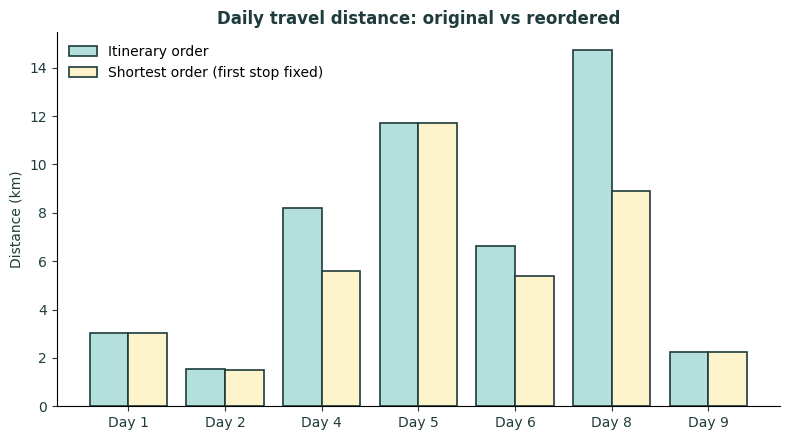

In [10]:
import matplotlib.pyplot as plt

TEAL = "#b3e0dc"
BUTTER = "#fdf4cb"
INK = "#1F3B3B"

days = [1, 2, 4, 5, 6, 8, 9]
before, after = [], []
for d in days:
    b, a, _ = best_order(d)
    before.append(b)
    after.append(a)

fig, ax = plt.subplots(figsize=(8, 4.5), facecolor="white")
x = range(len(days))
ax.bar([i - 0.2 for i in x], before, width=0.4, color=TEAL, edgecolor=INK, linewidth=1.2, label="Itinerary order")
ax.bar([i + 0.2 for i in x], after, width=0.4, color=BUTTER, edgecolor=INK, linewidth=1.2, label="Shortest order (first stop fixed)")
ax.set_xticks(list(x))
ax.set_xticklabels([f"Day {d}" for d in days], color=INK)
ax.set_ylabel("Distance (km)", color=INK)
ax.set_title("Daily travel distance: original vs reordered", color=INK, fontweight="bold")
ax.tick_params(colors=INK)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Totals across the 7 days I could measure

In [11]:
tot_b = tot_a = 0
for d in [1, 2, 4, 5, 6, 8, 9]:
    b, a, _ = best_order(d)
    print(d, round(b, 1), round(a, 1))
    tot_b += b
    tot_a += a
print("total", round(tot_b, 1), round(tot_a, 1), round((1 - tot_a / tot_b) * 100), "% shorter")

1 3.0 3.0
2 1.5 1.5
4 8.2 5.6
5 11.7 11.7
6 6.6 5.4
8 14.7 8.9
9 2.3 2.3
total 48.1 38.3 20 % shorter


## Takeaways
- 33 of 39 stops (85%) could be matched to a location. The rest were transit, vague entries ("Morning in Osaka"), or an outdated TeamLab listing.
- On the 7 days I could measure, reordering stops cut total straight-line distance from 48.1 km to 38.3 km (about 20%).
- The savings came from Days 4, 6 and 8. The biggest change was Day 8: 14.7 km down to 8.9 km. Days 1, 2, 5 and 9 did not improve.
- For the product: if posts carried real addresses, an app could flag days like Day 8 where the stop order makes the day longer than it needs to be.

**Limits:** approximate coordinates (15 of 32 distinct places spot-checked, 2 corrected), straight-line distance, one itinerary, and the first stop of each day is fixed. Testing alternate points for two large sites (Ueno Park, Ponto-cho Alley) left the result at about 20%.